# Ajuste de Umbral — Detector de Plagio

Notebook para encontrar el umbral óptimo del filtro matemático usando el **dev set sintético (60%)**.

**Objetivo:** maximizar el **recall** (no perder plagios reales), aceptando cierta caída en precisión.  
El umbral óptimo encontrado aquí se copia luego a `evaluar_sintetico.py` y `evaluar_clough.py`.

### Flujo
1. Carga el JSON de variantes y construye los pares del dev set
2. Ejecuta **solo el filtro matemático** (sin LLM) para todas las similitudes
3. Barre umbrales de 0.1 a 0.9 y calcula Precision, Recall y F-beta (β=2)
4. Muestra la curva y el umbral óptimo


In [1]:
import json
import random
import sys
from pathlib import Path
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Rutas del proyecto
DATA_DIR = Path("data")
FIG_DIR = DATA_DIR / "graficos"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def buscar_archivo(nombre):
    """Busca primero en data/ y después en el directorio actual."""
    for ruta in (DATA_DIR / nombre, Path(nombre)):
        if ruta.exists():
            return ruta
    return DATA_DIR / nombre

# Asegúrate de que detector_plagio.py está en el mismo directorio
sys.path.insert(0, ".")
from sistema.modulos.detector_plagio import limpiar_texto, calcular_trigramas, calcular_levenshtein_palabras
from sistema.config import JSON_DIR

# ── Parámetros ──────────────────────────────────────────────────────────────
ARCHIVO_VARIANTES = JSON_DIR / "respuestas_plagio.json"

SEED = 42
RATIO_DEV = 0.60   # 60% dev, 40% test
MIN_PALABRAS = 15
BETA = 2           # F-beta con beta=2 prioriza recall sobre precision


/home/ahervas2/practicas_uv/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ── Carga de variantes ──────────────────────────────────────────────────────
NIVELES_PLAGIO    = {"nivel_0", "nivel_1", "nivel_2", "nivel_3"}
NIVELES_NO_PLAGIO = {"nivel_4", "nivel_5"}

def cargar_variantes(ruta):
    """Carga las variantes desde un único archivo JSON."""
    with open(ruta, "r", encoding="utf-8") as f:
        return json.load(f)

def construir_pares(variantes):
    pares = []
    for task_id, perfiles in variantes.items():
        for perfil, datos in perfiles.items():
            original = datos.get("respuesta_original", "")
            vars_dict = datos.get("variantes") or {}
            for nivel, texto in vars_dict.items():
                if not texto:
                    continue
                pares.append({
                    "task_id": task_id, "perfil": perfil, "nivel": nivel,
                    "original": original, "variante": texto,
                    "etiqueta": "plagio" if nivel in NIVELES_PLAGIO else "no_plagio",
                })
    return pares

def split_dev(pares, seed=SEED, ratio_dev=RATIO_DEV):
    """
    Devuelve la partición de dev (60%) de forma ESTRATIFICADA por 'perfil'.
    Garantiza la misma proporción de respuestas de cada nivel en test y dev.
    """
    # 1. Agrupar las tareas únicas asociadas a cada perfil
    tareas_por_perfil = defaultdict(set)
    for p in pares:
        tareas_por_perfil[p["perfil"]].add(p["task_id"])

    # Establecer la semilla UNA sola vez antes de procesar para garantizar determinismo
    random.seed(seed)
    
    unidades_dev = set()

    # 2. Procesar cada perfil individualmente (ordenados alfabéticamente)
    for perfil in sorted(tareas_por_perfil.keys()):
        # Ordenar las tareas del perfil actual para asegurar que la semilla actúe igual
        tareas = sorted(list(tareas_por_perfil[perfil]))
        
        # Mezclar las tareas específicas de este perfil
        random.shuffle(tareas)
        
        # Calcular el punto de corte (ej. 60% para dev)
        n_dev = int(len(tareas) * ratio_dev)
        
        # OJO AQUÍ: Para DEV, tomamos las tareas HASTA el punto de corte
        for task_id in tareas[:n_dev]:
            unidades_dev.add((task_id, perfil))

    # 3. Filtrar la lista general conservando solo los que están en el conjunto de dev
    return [p for p in pares if (p["task_id"], p["perfil"]) in unidades_dev]

# --- Ejecución ---
variantes = cargar_variantes(ARCHIVO_VARIANTES)
pares     = construir_pares(variantes)
pares_dev = split_dev(pares)

print(f"Total pares construidos : {len(pares)}")
print(f"Pares en dev set (60%)  : {len(pares_dev)}")
print(f"  → Plagios reales      : {sum(1 for p in pares_dev if p['etiqueta'] == 'plagio')}")
print(f"  → No plagios reales   : {sum(1 for p in pares_dev if p['etiqueta'] == 'no_plagio')}")


Total pares construidos : 168
Pares en dev set (60%)  : 96
  → Plagios reales      : 64
  → No plagios reales   : 32


In [3]:
# ── Calcular similitudes (sin LLM) ──────────────────────────────────────────
registros = []
for par in pares_dev:
    w_orig = limpiar_texto(par["original"])
    w_var  = limpiar_texto(par["variante"])
    n_orig, n_var = len(w_orig), len(w_var)
    es_corto = n_orig < MIN_PALABRAS or n_var < MIN_PALABRAS

    if es_corto:
        sim = None   # pares cortos no pasan por filtro matemático
    else:
        sim_tri = calcular_trigramas(w_orig, w_var)
        sim_lev = calcular_levenshtein_palabras(w_orig, w_var)
        sim = max(sim_tri, sim_lev)

    registros.append({
        **par,
        "sim_maxima": sim,
        "es_corto": es_corto,
    })

n_cortos = sum(1 for r in registros if r["es_corto"])
print(f"Pares cortos (van directo al LLM, excluidos del barrido): {n_cortos}")
print(f"Pares con similitud calculada: {len(registros) - n_cortos}")


Pares cortos (van directo al LLM, excluidos del barrido): 0
Pares con similitud calculada: 96


In [4]:
# ── Barrido de umbrales ─────────────────────────────────────────────────────
# Solo sobre los pares con similitud calculada (excluimos los cortos)
registros_validos = [r for r in registros if not r["es_corto"]]

umbrales   = np.arange(0.10, 0.95, 0.05)
precisiones, recalls, fbetas = [], [], []

for t in umbrales:
    tp = fp = fn = tn = 0
    for r in registros_validos:
        pred    = "plagio" if r["sim_maxima"] >= t else "no_plagio"
        real    = r["etiqueta"]
        if pred == "plagio"    and real == "plagio":    tp += 1
        elif pred == "plagio"  and real == "no_plagio": fp += 1
        elif pred == "no_plagio" and real == "plagio":  fn += 1
        else:                                            tn += 1

    prec   = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec    = tp / (tp + fn) if (tp + fn) > 0 else 0
    fb     = (1 + BETA**2) * prec * rec / (BETA**2 * prec + rec) if (prec + rec) > 0 else 0

    precisiones.append(prec)
    recalls.append(rec)
    fbetas.append(fb)

# Umbral óptimo: el que maximiza F-beta
idx_opt   = int(np.argmax(fbetas))
t_optimo  = umbrales[idx_opt]
print(f"Umbral óptimo (max F{BETA}): {t_optimo:.2f}")
print(f"  Precision : {precisiones[idx_opt]:.3f}")
print(f"  Recall    : {recalls[idx_opt]:.3f}")
print(f"  F{BETA}       : {fbetas[idx_opt]:.3f}")


Umbral óptimo (max F2): 0.25
  Precision : 0.926
  Recall    : 0.984
  F2       : 0.972


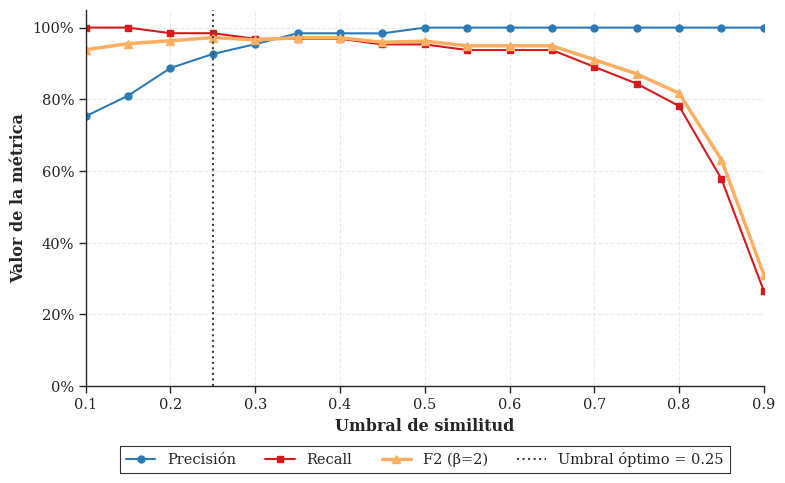

In [5]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# ── 1. Configuración de Estilo Académico ────────────────────────────────────
# Usamos Seaborn para una base limpia ("ticks" elimina la cuadrícula pesada)
sns.set_theme(style="ticks", context="paper", font_scale=1.2)

# Ajustes en matplotlib para emular el estilo LaTeX / Publicación científica
plt.rcParams.update({
    "font.family": "serif",       # Fuente Serif, ideal para documentos académicos
    "axes.spines.top": False,     # Eliminar borde superior
    "axes.spines.right": False,   # Eliminar borde derecho
    "axes.grid": True,            # Activar cuadrícula
    "grid.alpha": 0.4,            # Cuadrícula muy sutil
    "grid.linestyle": "--"        # Cuadrícula punteada para no distraer
})

# ── 2. Generación de la Gráfica ─────────────────────────────────────────────
# Tamaño estándar, un poco más ancho que alto (ideal para columnas de texto)
fig, ax = plt.subplots(figsize=(8, 5))

# Paleta de colores sobria, de alto contraste y "colorblind-friendly"
color_prec = "#2C7BB6"   # Azul clásico
color_rec = "#D7191C"    # Rojo profundo
color_fbeta = "#FDAE61"  # Naranja ocre
color_optimo = "#404040" # Gris oscuro (casi negro) para la referencia

# Trazado de las curvas con marcadores más pequeños y formales
ax.plot(umbrales, precisiones, marker="o", markersize=5, linestyle="-", 
        linewidth=1.5, label="Precisión", color=color_prec)

ax.plot(umbrales, recalls, marker="s", markersize=5, linestyle="-", 
        linewidth=1.5, label="Recall", color=color_rec)

# La métrica principal (F-beta) ligeramente más gruesa para destacar
ax.plot(umbrales, fbetas, marker="^", markersize=6, linestyle="-", 
        linewidth=2.5, label=f"F{BETA} (β={BETA})", color=color_fbeta)

# Línea del umbral óptimo (discreta pero clara)
ax.axvline(t_optimo, color=color_optimo, linestyle=":", linewidth=1.5,
           label=f"Umbral óptimo = {t_optimo:.2f}")

# ── 3. Etiquetas y Ejes ─────────────────────────────────────────────────────
ax.set_xlabel("Umbral de similitud", weight="bold")
ax.set_ylabel("Valor de la métrica", weight="bold")

# En los TFG el título de la figura suele ir en el pie de foto del documento, 
# pero si quieres título en la imagen, este es más sobrio:
#ax.set_title("Evolución de métricas de evaluación según umbral", pad=15, weight="bold")

# Eje Y en porcentaje y límites ajustados al 100%
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
ax.set_ylim(0, 1.05)
ax.set_xlim(min(umbrales), max(umbrales)) # Evita espacios en blanco a los lados

# Leyenda con caja sobria, bordes negros finos, ubicada fuera para no tapar datos
ax.legend(frameon=True, fancybox=False, edgecolor="black", 
          loc="lower center", bbox_to_anchor=(0.5, -0.25), ncol=4)

plt.tight_layout()

# ── 4. Guardado en Alta Calidad ─────────────────────────────────────────────
plt.savefig(FIG_DIR / "curva_umbral_tfg.png", dpi=300, bbox_inches="tight")

plt.show()

In [6]:
# ── Desglose por nivel de obfuscación con el umbral óptimo ─────────────────
print(f"Desglose con umbral óptimo = {t_optimo:.2f}\n")
print(f"{'Nivel':<12} {'Total':>6} {'Detectados':>11} {'Tasa detección':>15}")
print("-" * 48)

por_nivel = defaultdict(list)
for r in registros_validos:
    por_nivel[r["nivel"]].append(r)

for nivel in sorted(por_nivel.keys()):
    registros_nivel = por_nivel[nivel]
    detectados = sum(1 for r in registros_nivel if r["sim_maxima"] >= t_optimo)
    total      = len(registros_nivel)
    tasa       = detectados / total if total > 0 else 0
    es_plagio  = nivel in NIVELES_PLAGIO
    marca      = "✓ plagio" if es_plagio else "✗ no plagio"
    print(f"{nivel:<12} {total:>6} {detectados:>11} {tasa:>14.1%}  [{marca}]")

print(f"\n→ Copia este valor en evaluar_sintetico.py y evaluar_clough.py:")
print(f"   UMBRAL = {t_optimo:.2f}")


Desglose con umbral óptimo = 0.25

Nivel         Total  Detectados  Tasa detección
------------------------------------------------
nivel_0          16          16         100.0%  [✓ plagio]
nivel_1          16          15          93.8%  [✓ plagio]
nivel_2          16          16         100.0%  [✓ plagio]
nivel_3          16          16         100.0%  [✓ plagio]
nivel_4          16           3          18.8%  [✗ no plagio]
nivel_5          16           2          12.5%  [✗ no plagio]

→ Copia este valor en evaluar_sintetico.py y evaluar_clough.py:
   UMBRAL = 0.25


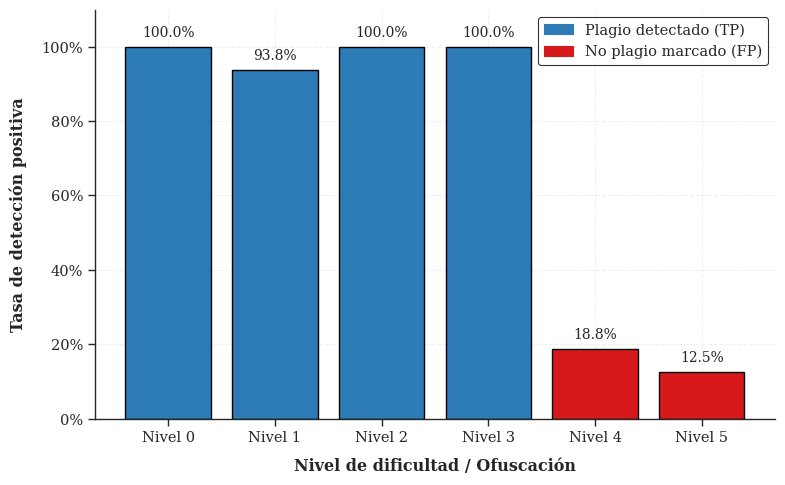

In [7]:
# ── Configuración de estilo académico ──
sns.set_theme(style="ticks", context="paper", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
    "axes.axisbelow": True # Para que la cuadrícula quede por debajo de las barras
})

# ── Preparación de datos ──
niveles_nombres = []
tasas = []
colores = []

# Colores aptos para daltonismo: Azul para aciertos (Plagio), Rojo apagado para falsos positivos (No Plagio)
color_plagio = "#2C7BB6" 
color_no_plagio = "#D7191C"

for nivel in sorted(por_nivel.keys()):
    registros_nivel = por_nivel[nivel]
    total = len(registros_nivel)
    detectados = sum(1 for r in registros_nivel if r["sim_maxima"] >= t_optimo)
    tasa = detectados / total if total > 0 else 0
    
    niveles_nombres.append(nivel.replace("_", " ").capitalize()) # Ej: "Nivel 0"
    tasas.append(tasa)
    colores.append(color_plagio if nivel in NIVELES_PLAGIO else color_no_plagio)

# ── Gráfica de Barras ──
fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(niveles_nombres, tasas, color=colores, edgecolor="black", linewidth=1)

# Ejes y formato
ax.set_xlabel("Nivel de dificultad / Ofuscación", weight="bold", labelpad=10)
ax.set_ylabel("Tasa de detección positiva", weight="bold", labelpad=10)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
ax.set_ylim(0, 1.1) # Damos un poco de aire por arriba

# Añadir el porcentaje exacto encima de cada barra
for barra in barras:
    altura = barra.get_height()
    ax.text(barra.get_x() + barra.get_width()/2., altura + 0.02,
            f"{altura:.1%}", ha='center', va='bottom', fontsize=10, family="serif")

# Leyenda personalizada
import matplotlib.patches as mpatches
patch_plagio = mpatches.Patch(color=color_plagio, label='Plagio detectado (TP)')
patch_no_plagio = mpatches.Patch(color=color_no_plagio, label='No plagio marcado (FP)')
ax.legend(handles=[patch_plagio, patch_no_plagio], loc='upper right', frameon=True, edgecolor="black")

plt.tight_layout()
plt.savefig(FIG_DIR / "tasa_deteccion_niveles.png", dpi=300, bbox_inches="tight")
plt.show()